# Зертханалық жұмыс №2
**Пән:** Компьютерлік көру (Computer Vision)

**Мақсаты:** кескіндегі шуды сүзу және сүзгілерді PSNR арқылы салыстыру, құжат фотосын әр түрлі әдіспен бинаризациялау, морфологиялық операциялармен маскадағы шу мен тесіктерді жою, Canny + findContours арқылы пішіндерді анықтау.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(42)


## 1-тапсырма: шуды сүзу және PSNR арқылы салыстыру

Өз фотоға екі түрлі шу қосамыз — **тұз бен бұрыш (salt & pepper)** және **Гаусс шуы (Gaussian)**, содан кейін әрқайсысын 4 сүзгімен (mean, Gaussian, median, bilateral) тазалап, нәтижелерді **PSNR** (Peak Signal-to-Noise Ratio) метрикасы арқылы түпнұсқамен салыстырамыз.

Тұз бен бұрыш шуы қосылған кескін PSNR: 19.81 дБ
Гаусс шуы қосылған кескін PSNR: 20.81 дБ


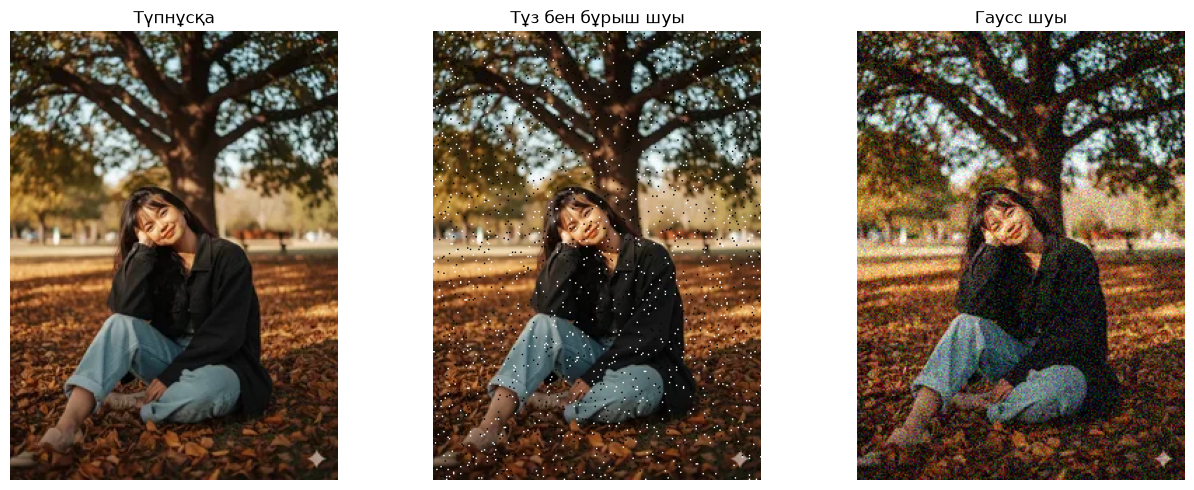

In [2]:
def add_salt_pepper_noise(image, amount=0.03):
    noisy = image.copy()
    h, w = image.shape[:2]
    n_pixels = int(amount * h * w)

    # 'Тұз' (ақ нүктелер)
    ys = np.random.randint(0, h, n_pixels // 2)
    xs = np.random.randint(0, w, n_pixels // 2)
    noisy[ys, xs] = 255

    # 'Бұрыш' (қара нүктелер)
    ys = np.random.randint(0, h, n_pixels // 2)
    xs = np.random.randint(0, w, n_pixels // 2)
    noisy[ys, xs] = 0

    return noisy


def add_gaussian_noise(image, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, image.shape)
    noisy = image.astype(np.float64) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


img = cv2.imread("images/photo.webp")
sp_noisy = add_salt_pepper_noise(img, amount=0.03)
gauss_noisy = add_gaussian_noise(img, mean=0, sigma=25)

print(f"Тұз бен бұрыш шуы қосылған кескін PSNR: {cv2.PSNR(img, sp_noisy):.2f} дБ")
print(f"Гаусс шуы қосылған кескін PSNR: {cv2.PSNR(img, gauss_noisy):.2f} дБ")

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, im, title in zip(axes, [img, sp_noisy, gauss_noisy],
                          ["Түпнұсқа", "Тұз бен бұрыш шуы", "Гаусс шуы"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_noisy_images.png"), bbox_inches="tight", dpi=120)
plt.show()


### 4 сүзгіні қолдану

- **Mean (box) filter** — көршілес пикселдердің орташасын алады, шуды жұмсартады, бірақ шеттерді де бұлдырлатады.
- **Gaussian filter** — Гаусс салмақтарымен орташалайды, Гаусс шуына жақсы келеді.
- **Median filter** — көршілердің медианасын алады, әсіресе **тұз бен бұрыш** шуын жоюда өте тиімді (шеткі мәндерге сезімтал емес).
- **Bilateral filter** — кеңістіктік және түс жақындығын бірге ескереді, шеттерді сақтай отырып тегістейді (ең баяу, бірақ сапалы).

Ядро өлшемі ретінде $5\times5$ (мед. сүзгі үшін де 5) таңдалды — бұл шуды жеткілікті басады, бірақ кескінді тым қатты бұлдырлатпайды.

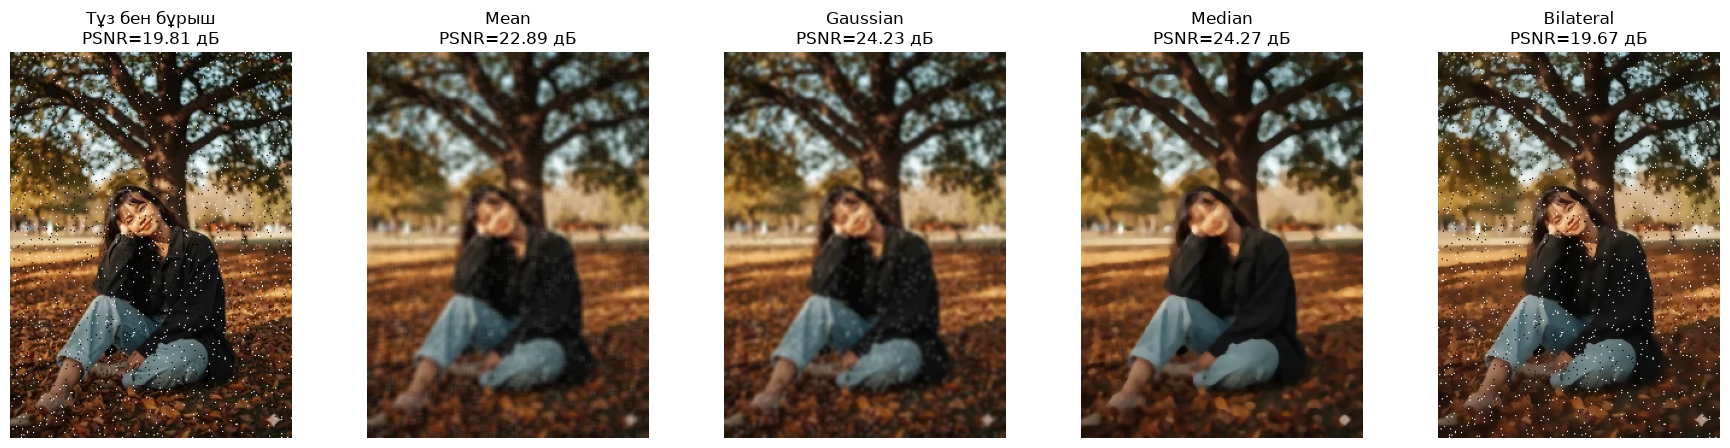

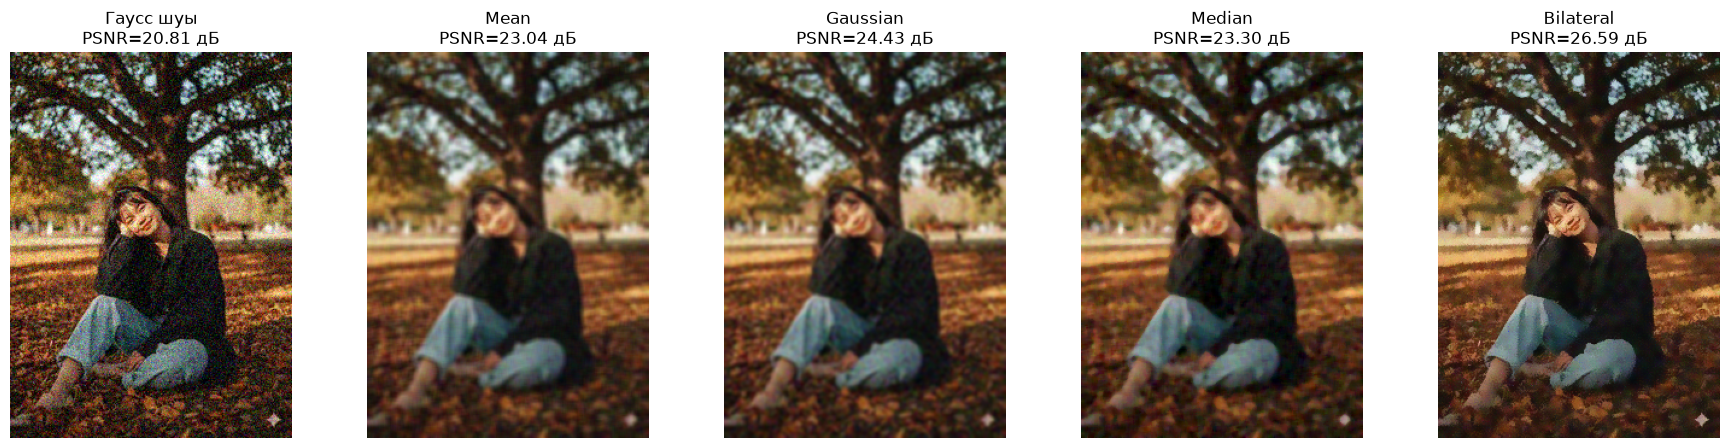

In [3]:
def apply_filters(noisy):
    mean_f = cv2.blur(noisy, (5, 5))
    gauss_f = cv2.GaussianBlur(noisy, (5, 5), sigmaX=1.5)
    median_f = cv2.medianBlur(noisy, 5)
    bilateral_f = cv2.bilateralFilter(noisy, d=9, sigmaColor=75, sigmaSpace=75)
    return {
        "Mean": mean_f,
        "Gaussian": gauss_f,
        "Median": median_f,
        "Bilateral": bilateral_f,
    }


def show_and_score(clean, noisy, filtered_dict, noise_name, filename):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
    axes[0].imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{noise_name}\nPSNR={cv2.PSNR(clean, noisy):.2f} дБ")
    axes[0].axis("off")

    scores = {}
    for ax, (name, filtered) in zip(axes[1:], filtered_dict.items()):
        psnr = cv2.PSNR(clean, filtered)
        scores[name] = psnr
        ax.imshow(cv2.cvtColor(filtered, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{name}\nPSNR={psnr:.2f} дБ")
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), bbox_inches="tight", dpi=120)
    plt.show()
    return scores


sp_filtered = apply_filters(sp_noisy)
sp_scores = show_and_score(img, sp_noisy, sp_filtered, "Тұз бен бұрыш",
                            "task1_salt_pepper_filters.png")

gauss_filtered = apply_filters(gauss_noisy)
gauss_scores = show_and_score(img, gauss_noisy, gauss_filtered, "Гаусс шуы",
                               "task1_gaussian_filters.png")


In [4]:
print(f"{'Сүзгі':<12}{'S&P PSNR (дБ)':>16}{'Gaussian PSNR (дБ)':>22}")
for name in sp_scores:
    print(f"{name:<12}{sp_scores[name]:>16.2f}{gauss_scores[name]:>22.2f}")

best_sp = max(sp_scores, key=sp_scores.get)
best_gauss = max(gauss_scores, key=gauss_scores.get)
print(f"\nТұз бен бұрыш шуы үшін ең жақсы сүзгі: {best_sp} (PSNR={sp_scores[best_sp]:.2f} дБ)")
print(f"Гаусс шуы үшін ең жақсы сүзгі: {best_gauss} (PSNR={gauss_scores[best_gauss]:.2f} дБ)")


Сүзгі          S&P PSNR (дБ)    Gaussian PSNR (дБ)
Mean                   22.89                 23.04
Gaussian               24.23                 24.43
Median                 24.27                 23.30
Bilateral              19.67                 26.59

Тұз бен бұрыш шуы үшін ең жақсы сүзгі: Median (PSNR=24.27 дБ)
Гаусс шуы үшін ең жақсы сүзгі: Bilateral (PSNR=26.59 дБ)


**Талдау:** Median сүзгі әдетте тұз бен бұрыш шуын жоюда ең жоғары PSNR береді, себебі бұл шу шеткі (outlier) мәндерден тұрады және медиана оларды толығымен алып тастайды. Ал Гаусс шуы үшін Gaussian және Bilateral сүзгілер тиімдірек, себебі шу үлестірімі де Гаусстық болғандықтан салмақталған орташалау жақсы нәтиже береді.

## 2-тапсырма: құжат фотосын бинаризациялау

Құжат фотосын үш әдіспен бинаризациялаймыз: **Global (тұрақты шек)**, **Otsu (автоматты оптималды шек)** және **Adaptive (аймаққа бейімделген шек)**.

Otsu әдісі таңдаған автоматты шек мәні: 130.0


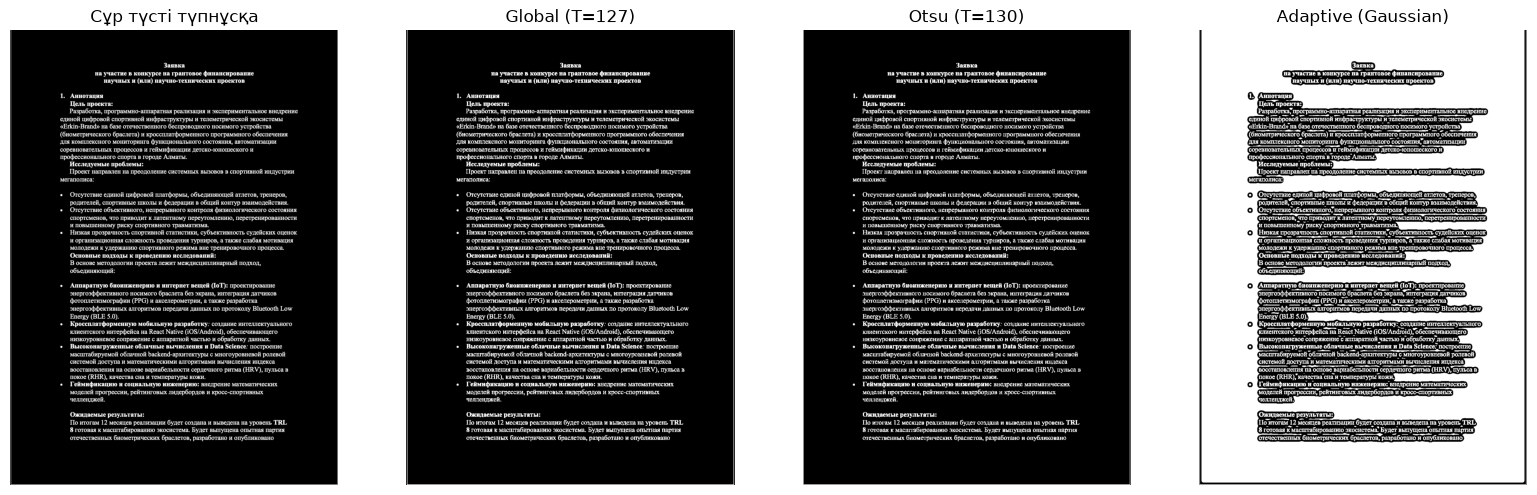

In [5]:
doc = cv2.imread("images/document.png")
doc_gray = cv2.cvtColor(doc, cv2.COLOR_BGR2GRAY)

# 1) Global thresholding — тұрақты шек мәні (гистограмма ортасына жақын таңдалды)
_, global_th = cv2.threshold(doc_gray, 127, 255, cv2.THRESH_BINARY)

# 2) Otsu thresholding — шек мәні автоматты түрде, гистограмманың
#    ішкі/сыртқы дисперсиясын минимизациялау арқылы таңдалады
otsu_value, otsu_th = cv2.threshold(doc_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 3) Adaptive thresholding — әр пиксель үшін шек мәні өз маңайының
#    орташасынан есептеледі (жарықтық біркелкі болмаса да жұмыс істейді)
adaptive_th = cv2.adaptiveThreshold(
    doc_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
    blockSize=25, C=10,
)

print(f"Otsu әдісі таңдаған автоматты шек мәні: {otsu_value:.1f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, im, title in zip(
    axes,
    [doc_gray, global_th, otsu_th, adaptive_th],
    ["Сұр түсті түпнұсқа", "Global (T=127)", f"Otsu (T={otsu_value:.0f})", "Adaptive (Gaussian)"],
):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_binarization.png"), bbox_inches="tight", dpi=120)
plt.show()


**Параметрлерді таңдау себебі және нәтиже талдауы:**

- Global әдісте $T=127$ — сұр диапазонның ($0..255$) дәл ортасы, бастапқы жуықтау ретінде қолданылды.
- Otsu әдісі шек мәнін гистограмма бойынша **автоматты** таңдайды (сынып-ішілік дисперсияны минимизациялайды); бұл суретте ол $T=130$ тапты — біздің қолмен таңдаған $T=127$ мәніне өте жақын, себебі фон (қараңғы) мен парақ (ашық) арасындағы гистограмма айқын екі шыңды (бимодальді).
- Adaptive (Gaussian) әдісінде `blockSize=25` және `C=10` таңдалды, бірақ нәтижеде мәтін айналасында шу/ореол пайда болды. Себебі: бұл құжат — біркелкі жарықтандырылған **скриншот**, сондықтан жергілікті бейімделудің қажеті жоқ, ал шектің әр аймақ үшін бөлек есептелуі осындай таза кескінде оптималдан гөрі көбірек шу қосады. **Adaptive әдістің шынайы артықшылығы** — көлеңкесі бар немесе жарықтығы бірыңғай емес нақты фотосуреттерде байқалады, мұндайда Global/Otsu бір ғана шекпен бүкіл кескінді дұрыс бөле алмайды, ал Adaptive әр аймаққа бейімделіп жақсы нәтиже береді. Бұл мысал — әдісті кескін сипатына қарай таңдау қажеттігінің көрінісі.

## 3-тапсырма: ашу және жабу арқылы бинарлы маскадағы шу мен тесіктерді жою

Нақты өмірде бинарлы маска әрдайым таза бола бермейді — оның үстінде ұсақ шу нүктелері (specks) және ішінде кішкентай тесіктер болуы мүмкін. Мұны көрсету үшін 2-тапсырмадағы Otsu маскасынан мәтіні бар аймақты қиып алып (жақынырақ көру үшін), оған жасанды тұз-бұрыш шуын қосамыз, содан кейін **ашу (opening = erosion → dilation)** арқылы ұсақ шу нүктелерін, ал **жабу (closing = dilation → erosion)** арқылы кішкентай тесіктерді жоямыз.

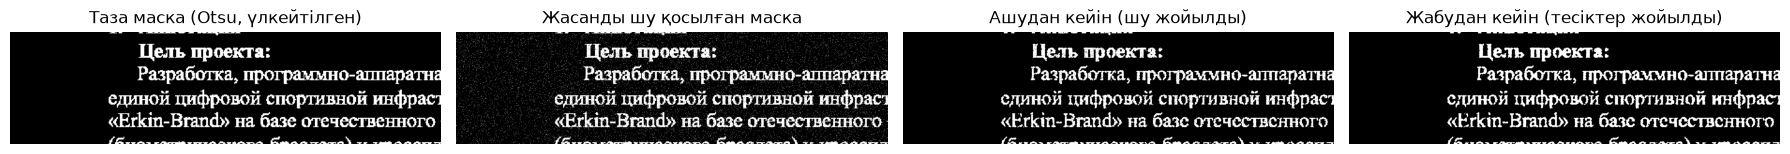

In [6]:
def add_binary_noise(binary_img, amount=0.03):
    noisy = binary_img.copy()
    h, w = noisy.shape
    n_pixels = int(amount * h * w)
    ys = np.random.randint(0, h, n_pixels)
    xs = np.random.randint(0, w, n_pixels)
    # Кездейсоқ пикселдерді керісінше мәнге ауыстырамыз (шу мен тесік құру үшін)
    noisy[ys, xs] = 255 - noisy[ys, xs]
    return noisy


# Мәтіні бар аймақты қиып аламыз — эффект айқынырақ көрінуі үшін
roi = otsu_th[220:340, 60:520]
roi_big = cv2.resize(roi, None, fx=2.5, fy=2.5, interpolation=cv2.INTER_NEAREST)

noisy_mask = add_binary_noise(roi_big, amount=0.03)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
opened = cv2.morphologyEx(noisy_mask, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for ax, im, title in zip(
    axes,
    [roi_big, noisy_mask, opened, closed],
    ["Таза маска (Otsu, үлкейтілген)", "Жасанды шу қосылған маска", "Ашудан кейін (шу жойылды)",
     "Жабудан кейін (тесіктер жойылды)"],
):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task3_morphology.png"), bbox_inches="tight", dpi=120)
plt.show()


**Параметрлерді таңдау себебі:** құрылымдық элемент ретінде $3\times3$ эллипс таңдалды — бұл өлшем қосылған шу нүктелерінің мөлшеріне сәйкес келеді әрі мәтіннің жіңішке штрихтарын толығымен жоймайды. Алдымен **ашу** қолданылды (ұсақ оқшауланған ақ нүктелерді — шуды — алып тастайды), содан кейін **жабу** (қалған фигуралар ішіндегі кішкентай қара тесіктерді толтырады). Ретін ауыстырса (алдымен жабу), шу нүктелері үлкен фигуралармен «жабысып», жойылмай қалуы мүмкін еді.

## 4-тапсырма: Canny + findContours арқылы пішіндерді анықтау

Әр түрлі геометриялық пішіндер (шеңбер, тіктөртбұрыш, шаршы, үшбұрыш, бесбұрыш) бейнеленген синтетикалық кескін жасап, оларды Canny шет анықтағышы мен `findContours` арқылы тауып, әр контурдың бұрыштар санына қарай түрін анықтаймыз.

Табылған контурлар саны: 5


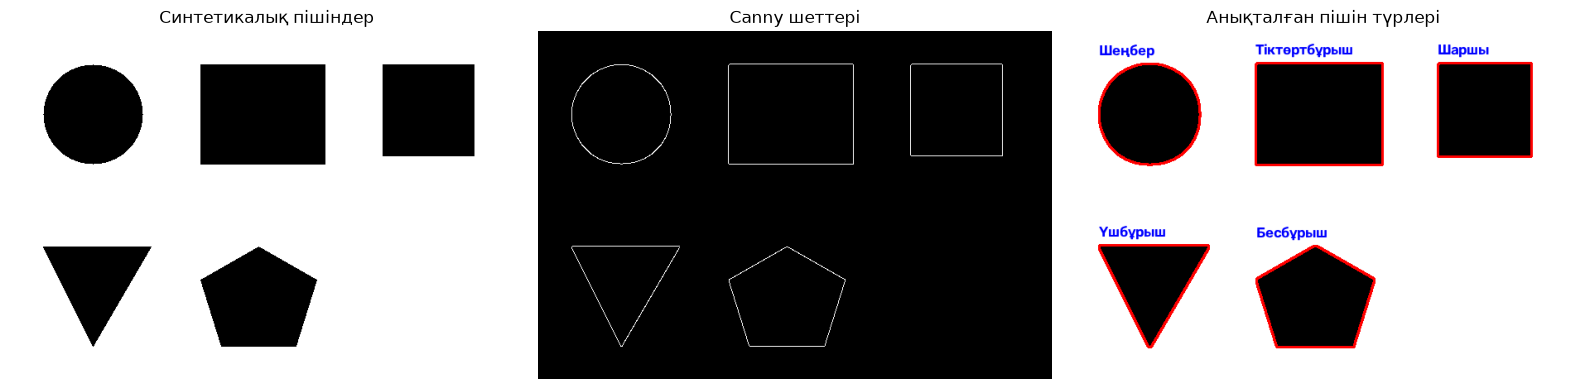

In [7]:
def make_shapes_image():
    canvas = np.full((420, 620, 3), 255, dtype=np.uint8)
    cv2.circle(canvas, (100, 100), 60, (0, 0, 0), -1)
    cv2.rectangle(canvas, (230, 40), (380, 160), (0, 0, 0), -1)          # тіктөртбұрыш
    cv2.rectangle(canvas, (450, 40), (560, 150), (0, 0, 0), -1)          # шаршы
    triangle = np.array([[100, 380], [40, 260], [170, 260]], np.int32)
    cv2.fillPoly(canvas, [triangle], (0, 0, 0))
    pentagon = np.array([[300, 260], [370, 300], [345, 380], [255, 380], [230, 300]], np.int32)
    cv2.fillPoly(canvas, [pentagon], (0, 0, 0))
    return canvas


def classify_shape(contour):
    peri = cv2.arcLength(contour, True)
    approx = cv2.approxPolyDP(contour, 0.03 * peri, True)
    vertices = len(approx)

    if vertices == 3:
        return "Үшбұрыш", approx
    if vertices == 4:
        x, y, w, h = cv2.boundingRect(approx)
        aspect_ratio = w / float(h)
        shape = "Шаршы" if 0.95 <= aspect_ratio <= 1.05 else "Тіктөртбұрыш"
        return shape, approx
    if vertices == 5:
        return "Бесбұрыш", approx

    area = cv2.contourArea(contour)
    circularity = 4 * np.pi * area / (peri ** 2) if peri > 0 else 0
    if circularity > 0.8:
        return "Шеңбер", approx
    return f"Көпбұрыш ({vertices})", approx


shapes_img = make_shapes_image()
gray_shapes = cv2.cvtColor(shapes_img, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray_shapes, 50, 150)
# Canny шеті 1 пиксель жіңішке болғандықтан, өткір бұрыштарда (мыс. үшбұрыш ұшы)
# контур дұрыс жабылмай, жалған (деградацияланған) контур пайда болуы мүмкін.
# Сондықтан findContours алдында шеттерді сәл dilate етеміз — бұл әдеттегі тәжірибе.
edges_dilated = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=1)
contours, _ = cv2.findContours(edges_dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

result = shapes_img.copy()
for cnt in contours:
    if cv2.contourArea(cnt) < 100:
        continue
    shape_name, approx = classify_shape(cnt)
    cv2.drawContours(result, [cnt], -1, (0, 0, 255), 2)
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.putText(result, shape_name, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX,
                0.6, (255, 0, 0), 2, cv2.LINE_AA)

print(f"Табылған контурлар саны: {len(contours)}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, im, title, cmap in zip(
    axes,
    [gray_shapes, edges, cv2.cvtColor(result, cv2.COLOR_BGR2RGB)],
    ["Синтетикалық пішіндер", "Canny шеттері", "Анықталған пішін түрлері"],
    ["gray", "gray", None],
):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_shape_detection.png"), bbox_inches="tight", dpi=120)
plt.show()


**Параметрлерді таңдау себебі:** Canny үшін төменгі/жоғарғы шектер `50/150` таңдалды — қатынасы шамамен $1{:}3$, бұл нақты пішінделген (шусыз) синтетикалық кескінде толық әрі үзіліссіз контур шеттерін береді. Шеттерді `findContours`-қа беру алдында $3\times3$ ядромен бір рет dilate жасадық — Canny сызығы небәрі 1 пиксель жіңішке болғандықтан, үшбұрыш ұшы сияқты өткір бұрыштарда контур дұрыс жабылмай, `contourArea`-сы жалған түрде тым кіші (деградацияланған) контур шығуы мүмкін еді — dilate осы мәселені шешеді. `approxPolyDP`-де $\varepsilon = 0.03 \times$ периметр алынды — бұл мәннің тым кіші болуы контурды тым көп бұрышты қылады (шеңберді көпбұрыш деп қате анықтайды), ал тым үлкен болуы нақты бұрыштарды жоғалтады. Шаршы мен тіктөртбұрышты ажырату үшін қоршаушы тіктөртбұрыштың ен/бойы қатынасы (aspect ratio) 1-ге жақын (0.95–1.05) болса — шаршы, әйтпесе тіктөртбұрыш деп есептелді. Дөңгелектілік коэффициенті ($4\pi \cdot S / P^2$, 1-ге неғұрлым жақын болса, соғұрлым шеңберге ұқсас) арқылы шеңбер көпбұрыштардан ажыратылды.

## Жалпы қорытынды

Бұл зертханалық жұмыста кескінді өңдеудің төрт негізгі бағыты қарастырылды. Біріншіден, шуды сүзу тәжірибесі көрсеткендей, сүзгі түрін шу сипатына қарай таңдау маңызды — median сүзгі тұз-бұрыш шуын, ал Gaussian/bilateral сүзгілер Гаусс шуын тиімдірек басады, бұл PSNR мәндерімен нақты расталды. Екіншіден, құжатты бинаризациялауда Otsu әдісі шек мәнін автоматты түрде оптимал таңдайды, ал Adaptive әдіс жарықтығы біркелкі емес кескіндерде ең тұрақты нәтиже береді. Үшіншіден, морфологиялық ашу және жабу операциялары бинарлы маскадағы шу мен тесіктерді сәтті жойып, маска сапасын айтарлықтай жақсартты. Соңында, Canny шет анықтағышы мен `findContours`/`approxPolyDP` комбинациясы арқылы геометриялық пішіндерді олардың бұрыштар саны мен дөңгелектілігі бойынша дәл ажыратуға болатыны көрсетілді.